In [1]:
import pandas as pd


In [ ]:
In [1]:

In [2]:
df = pd.read_csv("Amazon.csv")

In [3]:
df.head()

,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.59,0.00,0.00,0.09,319.86,Debit Card,Delivered,Washington,DC,India,SELL01967
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.37,0.05,19.10,1.74,259.64,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.03,0.10,7.57,5.91,108.06,Debit Card,Delivered,Austin,TX,United States,SELL00908
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.58,0.15,11.42,5.53,159.66,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164
4,ORD0000005,2023-02-04,CUST048677,Aditya Kapoor,P00029,T-Shirt,Clothing,KiddoFun,2,515.64,0.25,38.67,9.23,821.36,Credit Card,Cancelled,San Antonio,TX,Canada,SELL01411


In [4]:
df.shape


(100000, 20)

In [5]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerID', 'CustomerName', 'ProductID',
       'ProductName', 'Category', 'Brand', 'Quantity', 'UnitPrice', 'Discount',
       'Tax', 'ShippingCost', 'TotalAmount', 'PaymentMethod', 'OrderStatus',
       'City', 'State', 'Country', 'SellerID'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   OrderID        100000 non-null  str    
 1   OrderDate      100000 non-null  str    
 2   CustomerID     100000 non-null  str    
 3   CustomerName   100000 non-null  str    
 4   ProductID      100000 non-null  str    
 5   ProductName    100000 non-null  str    
 6   Category       100000 non-null  str    
 7   Brand          100000 non-null  str    
 8   Quantity       100000 non-null  int64  
 9   UnitPrice      100000 non-null  float64
 10  Discount       100000 non-null  float64
 11  Tax            100000 non-null  float64
 12  ShippingCost   100000 non-null  float64
 13  TotalAmount    100000 non-null  float64
 14  PaymentMethod  100000 non-null  str    
 15  OrderStatus    100000 non-null  str    
 16  City           100000 non-null  str    
 17  State          100000 non-null  str    
 

In [7]:
df.duplicated().sum()


np.int64(0)

In [8]:
df["OrderDate"].min(), df["OrderDate"].max()

('2020-01-01', '2024-12-29')

In [10]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

In [11]:
df["OrderDate"].dtype

dtype('<M8[us]')

In [12]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

In [13]:
df["OrderDate"].dtype

dtype('<M8[us]')

In [14]:
df["OrderStatus"].value_counts()

OrderStatus
Delivered    74628
Shipped      15192
Pending       4103
Returned      3049
Cancelled     3028
Name: count, dtype: int64

In [15]:
pd.crosstab(df["Category"], df["OrderStatus"])

OrderStatus,Cancelled,Delivered,Pending,Returned,Shipped
Category,,,,,
Books,500,12536,646,523,2547
Clothing,467,12296,646,504,2526
Electronics,544,12618,693,475,2523
Home & Kitchen,508,12330,690,534,2548
Sports & Outdoors,497,12568,718,518,2503
Toys & Games,512,12280,710,495,2545


In [16]:
pd.crosstab(
    df["Category"],
    df["OrderStatus"],
    normalize="index"
).round(4) * 100


OrderStatus,Cancelled,Delivered,Pending,Returned,Shipped
Category,,,,,
Books,2.98,74.83,3.86,3.12,15.20
Clothing,2.84,74.80,3.93,3.07,15.37
Electronics,3.23,74.87,4.11,2.82,14.97
Home & Kitchen,3.06,74.23,4.15,3.21,15.34
Sports & Outdoors,2.96,74.79,4.27,3.08,14.90
Toys & Games,3.10,74.24,4.29,2.99,15.39


In [17]:
df["State"].value_counts()

State
TX    24896
CA    19921
NC     5110
FL     5107
WA     5039
DC     5021
OH     5021
IL     5020
PA     5014
CO     4991
IN     4970
NY     4949
AZ     4941
Name: count, dtype: int64

In [18]:
pd.crosstab(
    df["State"],
    df["OrderStatus"],
    normalize="index"
).round(4) * 100

OrderStatus,Cancelled,Delivered,Pending,Returned,Shipped
State,,,,,
AZ,2.79,73.97,4.41,3.20,15.62
CA,2.96,74.64,4.19,3.36,14.84
CO,3.33,74.79,3.57,3.21,15.11
DC,3.33,74.03,4.48,3.13,15.04
FL,3.02,75.00,4.15,2.96,14.88
IL,2.77,74.80,4.00,3.25,15.18
IN,3.56,74.65,4.25,2.96,14.59
NC,2.62,75.24,3.74,2.88,15.52
NY,3.37,75.49,3.64,2.75,14.75


In [19]:
pd.crosstab(
    [df["State"], df["Category"]],
    df["OrderStatus"],
    normalize="index"
).round(4) * 100

OrderStatus              Cancelled  Delivered  Pending  Returned  Shipped
State Category                                                           
AZ    Books                   3.42      75.32     3.66      2.95    14.64
      Clothing                3.58      68.97     5.04      4.51    17.90
      Electronics             3.08      75.27     3.79      2.84    15.03
      Home & Kitchen          2.73      74.32     4.84      2.98    15.14
      Sports & Outdoors       1.79      75.51     4.36      2.95    15.38
...                            ...        ...      ...       ...      ...
WA    Clothing                2.86      76.49     2.24      3.48    14.93
      Electronics             3.69      73.32     3.15      3.04    16.81
      Home & Kitchen          3.19      72.92     4.21      3.07    16.61
      Sports & Outdoors       2.89      73.50     5.32      3.82    14.47
      Toys & Games            2.47      74.81     5.19      2.34    15.19

[78 rows x 5 columns]

In [20]:
rate = pd.crosstab(
    [df["State"], df["Category"]],
    df["OrderStatus"],
    normalize="index"
) * 100

rate["Cancelled"].sort_values(ascending=False).head(10)

State  Category         
OH     Sports & Outdoors    4.582844
IN     Toys & Games         4.498715
OH     Books                4.337632
NY     Books                4.305043
       Clothing             4.134367
CO     Sports & Outdoors    4.119850
DC     Electronics          4.038005
       Home & Kitchen       3.952096
IN     Electronics          3.947368
       Home & Kitchen       3.869407
Name: Cancelled, dtype: float64

In [21]:
segment = (
    df.groupby(["State", "Category"])
      .agg(
          TotalOrders=("OrderID", "count"),
          CancelledOrders=("OrderStatus", lambda x: (x == "Cancelled").sum())
      )
)

segment["CancelledRate"] = (
    segment["CancelledOrders"] / segment["TotalOrders"] * 100
)

segment.sort_values("CancelledRate", ascending=False).head(10)



TotalOrders  CancelledOrders  CancelledRate
State Category                                                      
OH    Sports & Outdoors          851               39       4.582844
IN    Toys & Games               778               35       4.498715
OH    Books                      853               37       4.337632
NY    Books                      813               35       4.305043
      Clothing                   774               32       4.134367
CO    Sports & Outdoors          801               33       4.119850
DC    Electronics                842               34       4.038005
      Home & Kitchen             835               33       3.952096
IN    Electronics                836               33       3.947368
      Home & Kitchen             827               32       3.869407

In [22]:
overall_cancel_rate = (df["OrderStatus"] == "Cancelled").mean() * 100

print("Overall cancellation rate:", round(overall_cancel_rate, 2), "%")

Overall cancellation rate: 3.03 %


In [23]:
oh_sports = df[
    (df["State"] == "OH") &
    (df["Category"] == "Sports & Outdoors")
]

product_cancel = (
    oh_sports.groupby("ProductName")
    .agg(
        TotalOrders=("OrderID", "count"),
        CancelledOrders=("OrderStatus", lambda x: (x == "Cancelled").sum())
    )
)

product_cancel["CancellationRate"] = (
    product_cancel["CancelledOrders"] /
    product_cancel["TotalOrders"] * 100
)

product_cancel.sort_values(
    "CancellationRate",
    ascending=False
).head(10)

,TotalOrders,CancelledOrders,CancellationRate
ProductName,,,
Wireless Earbuds,19,3,15.789474
LED Desk Lamp,13,2,15.384615
Gaming Mouse,25,3,12.000000
Winter Jacket,17,2,11.764706
Smartphone Case,18,2,11.111111
Kids Toy Car,21,2,9.523810
Graphic Tablet,22,2,9.090909
Electric Kettle,11,1,9.090909
Yoga Mat,12,1,8.333333


In [25]:
product_cancel_50 = product_cancel[
    product_cancel["TotalOrders"] >= 50
].sort_values(
    "CancellationRate",
    ascending=False
)

product_cancel_50.head(10)

,TotalOrders,CancelledOrders,CancellationRate
ProductName,,,


In [26]:
product_overall = df.groupby("ProductName").agg(
    TotalOrders=("OrderID", "count"),
    CancelledOrders=("OrderStatus", lambda x: (x == "Cancelled").sum())
)

product_overall["CancellationRate"] = (
    product_overall["CancelledOrders"] /
    product_overall["TotalOrders"] * 100
)

product_overall.sort_values(
    "CancellationRate",
    ascending=False
).head(15)

,TotalOrders,CancelledOrders,CancellationRate
ProductName,,,
4K Monitor,2006,78,3.888335
Gaming Mouse,2010,76,3.781095
Dress Shirt,2007,75,3.736921
Backpack,1910,71,3.717277
Children's Book,1914,70,3.657262
Sunglasses,1952,69,3.534836
Electric Kettle,2054,70,3.407984
HDMI Cable 2m,2002,68,3.396603
Vacuum Cleaner,2017,68,3.371344


In [27]:
payment_cancel = df.groupby("PaymentMethod").agg(
    TotalOrders=("OrderID", "count"),
    CancelledOrders=("OrderStatus", lambda x: (x == "Cancelled").sum())
)

payment_cancel["CancellationRate"] = (
    payment_cancel["CancelledOrders"] /
    payment_cancel["TotalOrders"] * 100
)

payment_cancel.sort_values(
    "CancellationRate",
    ascending=False
).round(2)

,TotalOrders,CancelledOrders,CancellationRate
PaymentMethod,,,
Cash on Delivery,4928,156,3.17
Credit Card,35038,1083,3.09
Amazon Pay,15017,461,3.07
Debit Card,20024,593,2.96
UPI,15066,444,2.95
Net Banking,9927,291,2.93


In [28]:
sales_summary = df.groupby("Category").agg(
    TotalOrders=("OrderID", "count"),
    TotalQuantity=("Quantity", "sum"),
    TotalRevenue=("TotalAmount", "sum")
).sort_values("TotalRevenue", ascending=False)

sales_summary.round(2)

,TotalOrders,TotalQuantity,TotalRevenue
Category,,,
Electronics,16853,50696,15584217.18
Sports & Outdoors,16804,50543,15345571.88
Books,16752,49981,15261837.01
Clothing,16439,49523,15253397.50
Toys & Games,16542,49773,15216684.99
Home & Kitchen,16610,49624,15163939.36


In [29]:
monthly_sales = df.groupby(
    df["OrderDate"].dt.to_period("M")
).agg(
    TotalOrders=("OrderID", "count"),
    TotalRevenue=("TotalAmount", "sum")
).reset_index()

monthly_sales["OrderDate"] = monthly_sales["OrderDate"].astype(str)

monthly_sales


,OrderDate,TotalOrders,TotalRevenue
0,2020-01,1730,1637069.40
1,2020-02,1490,1339388.21
2,2020-03,1685,1587125.66
3,2020-04,1692,1588347.29
4,2020-05,1672,1533834.17
5,2020-06,1633,1500269.29
6,2020-07,1687,1552981.94
7,2020-08,1783,1640874.93
8,2020-09,1679,1554682.21
9,2020-10,1647,1515403.62


In [30]:
highest_month = monthly_sales.loc[
    monthly_sales["TotalRevenue"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["TotalRevenue"].idxmin()
]

print("Highest Revenue Month:")
print(highest_month)

print("\nLowest Revenue Month:")
print(lowest_month)

Highest Revenue Month:
OrderDate          2024-05
TotalOrders           1753
TotalRevenue    1642609.94
Name: 52, dtype: object

Lowest Revenue Month:
OrderDate          2020-02
TotalOrders           1490
TotalRevenue    1339388.21
Name: 1, dtype: object


In [31]:
yearly_sales = df.groupby(
    df["OrderDate"].dt.year
).agg(
    TotalOrders=("OrderID", "count"),
    TotalRevenue=("TotalAmount", "sum")
).reset_index()

yearly_sales["YoYGrowth"] = (
    yearly_sales["TotalRevenue"].pct_change() * 100
)

yearly_sales.round(2)

,OrderDate,TotalOrders,TotalRevenue,YoYGrowth
0,2020,20066,18529864.02,NaN
1,2021,19890,18248574.81,-1.52
2,2022,20078,18367248.41,0.65
3,2023,20096,18513912.19,0.80
4,2024,19870,18166048.49,-1.88


In [32]:
category_revenue = df.groupby("Category").agg(
    TotalOrders=("OrderID", "count"),
    TotalRevenue=("TotalAmount", "sum")
).sort_values(
    "TotalRevenue",
    ascending=False
)

category_revenue["RevenueShare"] = (
    category_revenue["TotalRevenue"]
    / category_revenue["TotalRevenue"].sum()
    * 100
)

category_revenue.round(2)

,TotalOrders,TotalRevenue,RevenueShare
Category,,,
Electronics,16853,15584217.18,16.97
Sports & Outdoors,16804,15345571.88,16.71
Books,16752,15261837.01,16.62
Clothing,16439,15253397.50,16.61
Toys & Games,16542,15216684.99,16.57
Home & Kitchen,16610,15163939.36,16.51


In [33]:
payment_category = pd.crosstab(
    df["Category"],
    df["PaymentMethod"]
)

payment_category

PaymentMethod,Amazon Pay,Cash on Delivery,Credit Card,Debit Card,Net Banking,UPI
Category,,,,,,
Books,2599,807,5939,3354,1636,2417
Clothing,2479,813,5811,3298,1646,2392
Electronics,2485,851,5900,3409,1633,2575
Home & Kitchen,2517,819,5766,3318,1689,2501
Sports & Outdoors,2487,862,5916,3327,1645,2567
Toys & Games,2450,776,5706,3318,1678,2614


In [34]:
payment_cancel = df.groupby("PaymentMethod").agg(
    TotalOrders=("OrderID", "count"),
    CancelledOrders=("OrderStatus", lambda x: (x == "Cancelled").sum())
)

payment_cancel["CancellationRate"] = (
    payment_cancel["CancelledOrders"]
    / payment_cancel["TotalOrders"]
    * 100
)

payment_cancel.sort_values(
    "CancellationRate",
    ascending=False
).round(2)

,TotalOrders,CancelledOrders,CancellationRate
PaymentMethod,,,
Cash on Delivery,4928,156,3.17
Credit Card,35038,1083,3.09
Amazon Pay,15017,461,3.07
Debit Card,20024,593,2.96
UPI,15066,444,2.95
Net Banking,9927,291,2.93


In [35]:
product_performance = df.groupby("ProductName").agg(
    TotalOrders=("OrderID", "count"),
    TotalRevenue=("TotalAmount", "sum"),
    CancelledOrders=("OrderStatus", lambda x: (x == "Cancelled").sum())
)

product_performance["CancellationRate"] = (
    product_performance["CancelledOrders"]
    / product_performance["TotalOrders"]
    * 100
)

product_performance.sort_values(
    "TotalRevenue",
    ascending=False
).head(15).round(2)

,TotalOrders,TotalRevenue,CancelledOrders,CancellationRate
ProductName,,,,
Memory Card 128GB,2039,1935138.40,68,3.33
LED Desk Lamp,2098,1921948.41,58,2.76
Mechanical Keyboard,2034,1906963.54,66,3.24
Electric Kettle,2054,1905751.79,70,3.41
Smartwatch,1989,1901275.59,53,2.66
Dress Shirt,2007,1896765.36,75,3.74
Water Bottle,2088,1895467.95,69,3.30
Gaming Mouse,2010,1895103.98,76,3.78
Kids Toy Car,2004,1891082.43,59,2.94


In [36]:
state_category_cancel = pd.crosstab(
    [df["State"], df["Category"]],
    df["OrderStatus"],
    normalize="index"
) * 100

state_category_cancel["Cancelled"] = (
    state_category_cancel["Cancelled"]
)

state_category_cancel[["Cancelled"]].sort_values(
    "Cancelled",
    ascending=False
).head(15).round(2)

OrderStatus              Cancelled
State Category                    
OH    Sports & Outdoors       4.58
IN    Toys & Games            4.50
OH    Books                   4.34
NY    Books                   4.31
      Clothing                4.13
CO    Sports & Outdoors       4.12
DC    Electronics             4.04
      Home & Kitchen          3.95
IN    Electronics             3.95
      Home & Kitchen          3.87
FL    Toys & Games            3.78
WA    Electronics             3.69
AZ    Clothing                3.58
TX    Toys & Games            3.58
FL    Sports & Outdoors       3.58

In [37]:
customer_analysis = df.groupby("CustomerID").agg(
    TotalOrders=("OrderID", "count"),
    TotalRevenue=("TotalAmount", "sum")
)

customer_analysis["CustomerType"] = customer_analysis["TotalOrders"].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)

customer_analysis["CustomerType"].value_counts()

CustomerType
Repeat Customer      29701
One-Time Customer    13532
Name: count, dtype: int64

In [38]:
customer_revenue = customer_analysis.groupby("CustomerType").agg(
    Customers=("TotalOrders", "count"),
    TotalOrders=("TotalOrders", "sum"),
    TotalRevenue=("TotalRevenue", "sum")
)

customer_revenue["RevenueShare"] = (
    customer_revenue["TotalRevenue"]
    / customer_revenue["TotalRevenue"].sum()
    * 100
)

customer_revenue.round(2)

,Customers,TotalOrders,TotalRevenue,RevenueShare
CustomerType,,,,
One-Time Customer,13532,13532,12458289.92,13.57
Repeat Customer,29701,86468,79367358.00,86.43


In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

category_revenue = df.groupby("Category")["TotalAmount"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index
)

plt.title("Revenue by Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

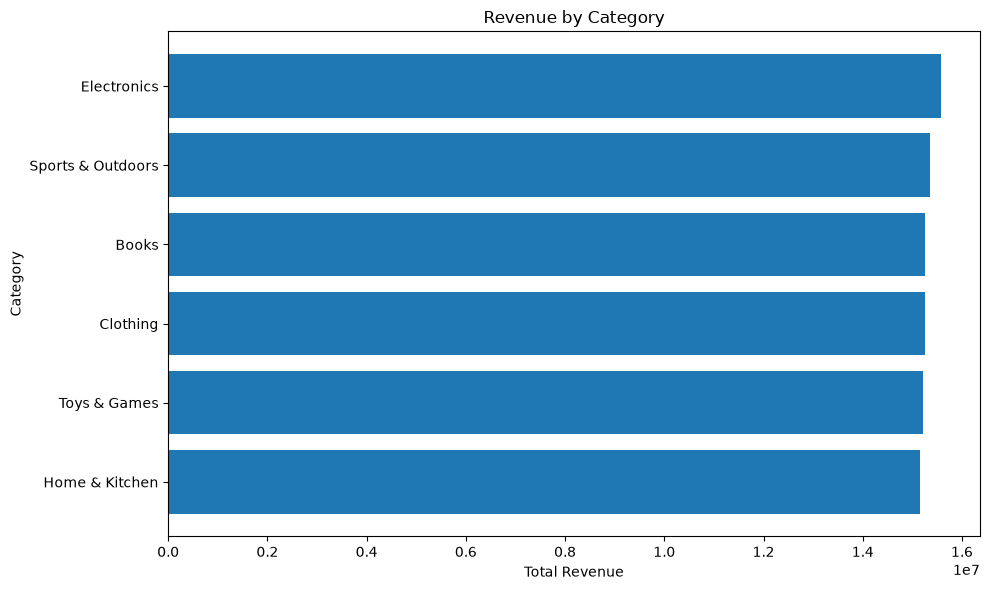

In [40]:
import matplotlib.pyplot as plt

category_revenue = (
    df.groupby("Category")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_revenue.index,
    category_revenue.values
)

plt.title("Revenue by Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

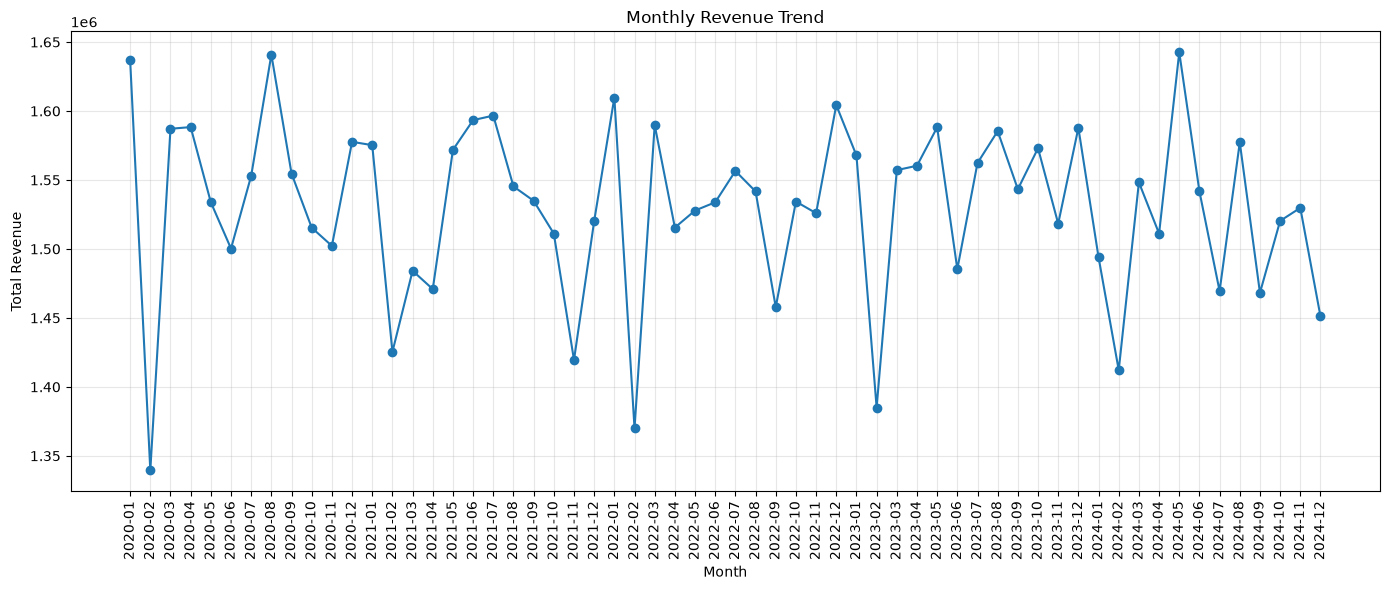

In [41]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["OrderDate"].astype(str),
    monthly_sales["TotalRevenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

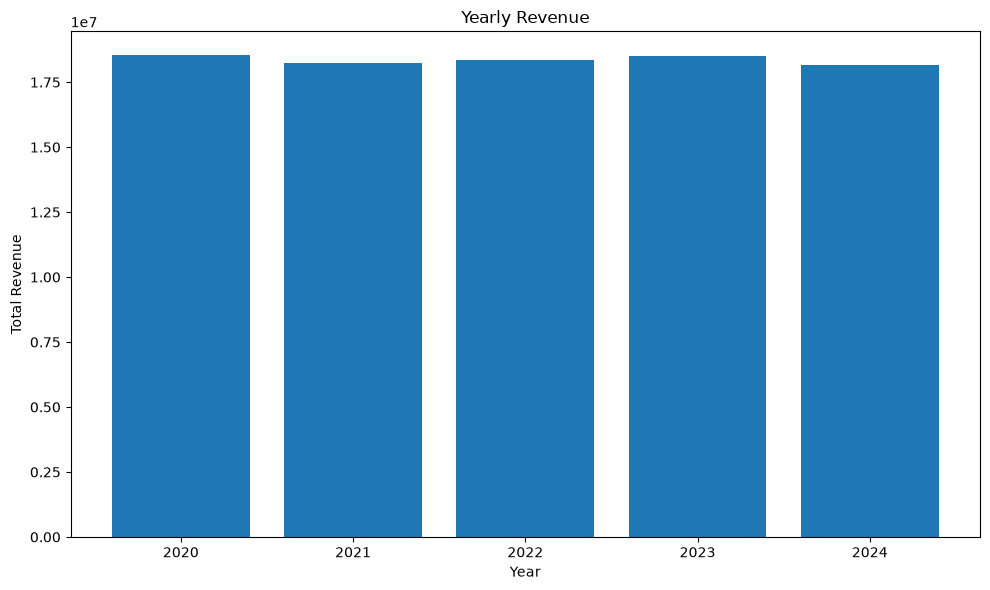

In [42]:
plt.figure(figsize=(10, 6))

plt.bar(
    yearly_sales["OrderDate"].astype(str),
    yearly_sales["TotalRevenue"]
)

plt.title("Yearly Revenue")
plt.xlabel("Year")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

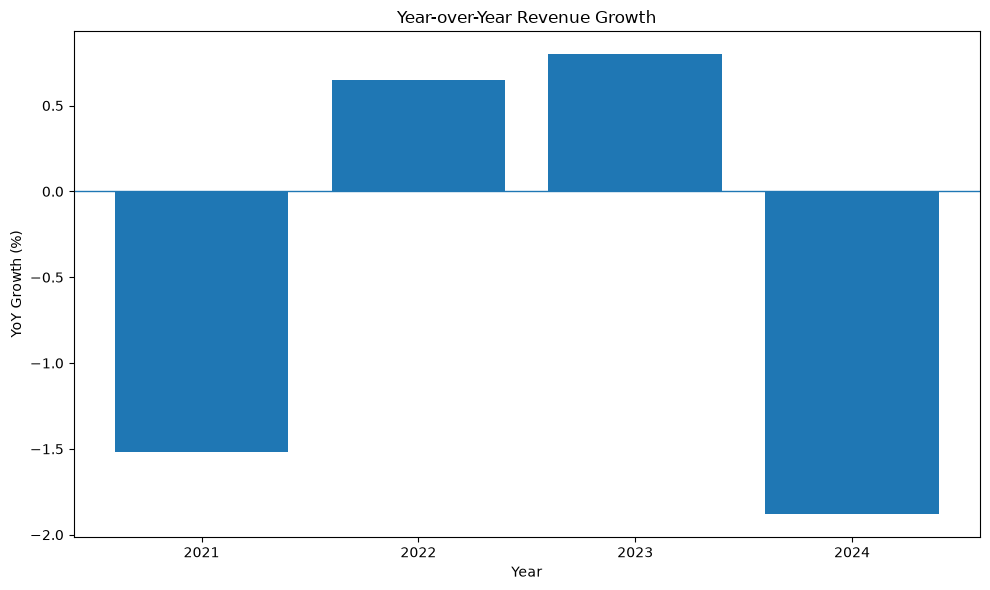

In [43]:
plt.figure(figsize=(10, 6))

plt.bar(
    yearly_sales["OrderDate"].astype(str),
    yearly_sales["YoYGrowth"]
)

plt.axhline(0, linewidth=1)

plt.title("Year-over-Year Revenue Growth")
plt.xlabel("Year")
plt.ylabel("YoY Growth (%)")

plt.tight_layout()
plt.show()

In [44]:
plt.figure(figsize=(8, 6))

plt.bar(
    customer_revenue["CustomerType"],
    customer_revenue["TotalRevenue"]
)

plt.title("Revenue by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

KeyError: 'CustomerType'

<Figure size 800x600 with 0 Axes>

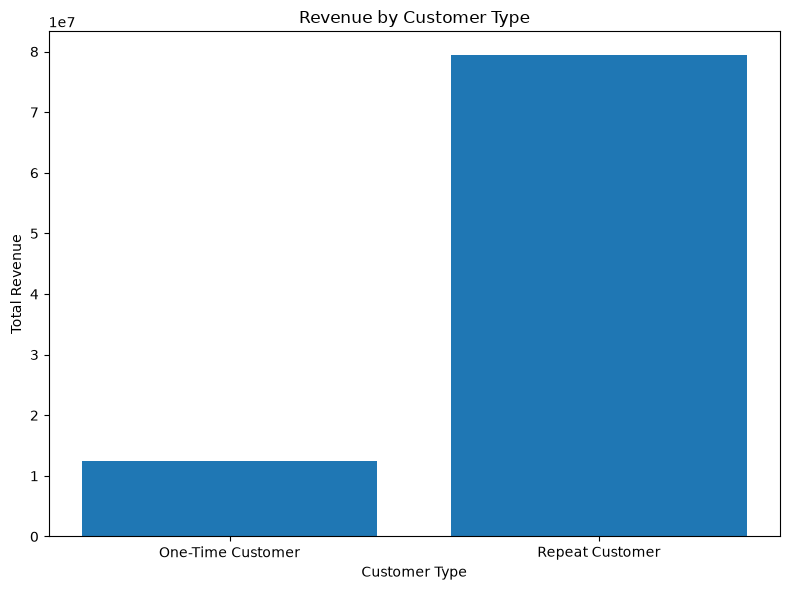

In [45]:
plt.figure(figsize=(8, 6))

plt.bar(
    customer_revenue.index,
    customer_revenue["TotalRevenue"]
)

plt.title("Revenue by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

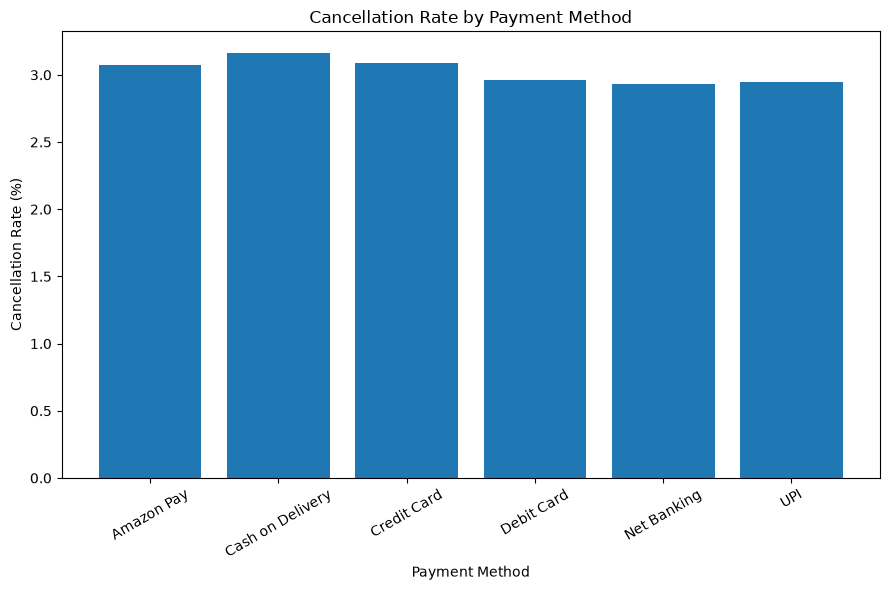

In [46]:
plt.figure(figsize=(9, 6))

plt.bar(
    payment_cancel.index,
    payment_cancel["CancellationRate"]
)

plt.title("Cancellation Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

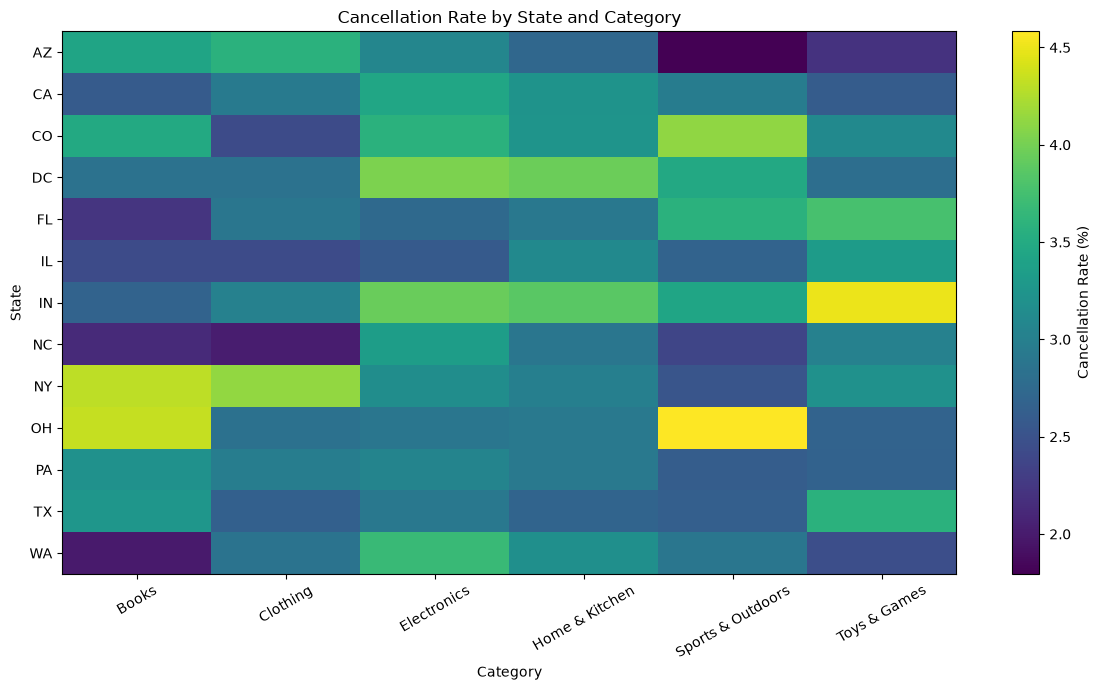

In [47]:
state_category_cancel = (
    df.groupby(["State", "Category"])["OrderStatus"]
    .apply(lambda x: (x == "Cancelled").mean() * 100)
    .unstack()
)

plt.figure(figsize=(12, 7))

plt.imshow(state_category_cancel, aspect="auto")

plt.colorbar(label="Cancellation Rate (%)")

plt.xticks(
    range(len(state_category_cancel.columns)),
    state_category_cancel.columns,
    rotation=30
)

plt.yticks(
    range(len(state_category_cancel.index)),
    state_category_cancel.index
)

plt.title("Cancellation Rate by State and Category")
plt.xlabel("Category")
plt.ylabel("State")

plt.tight_layout()
plt.show()

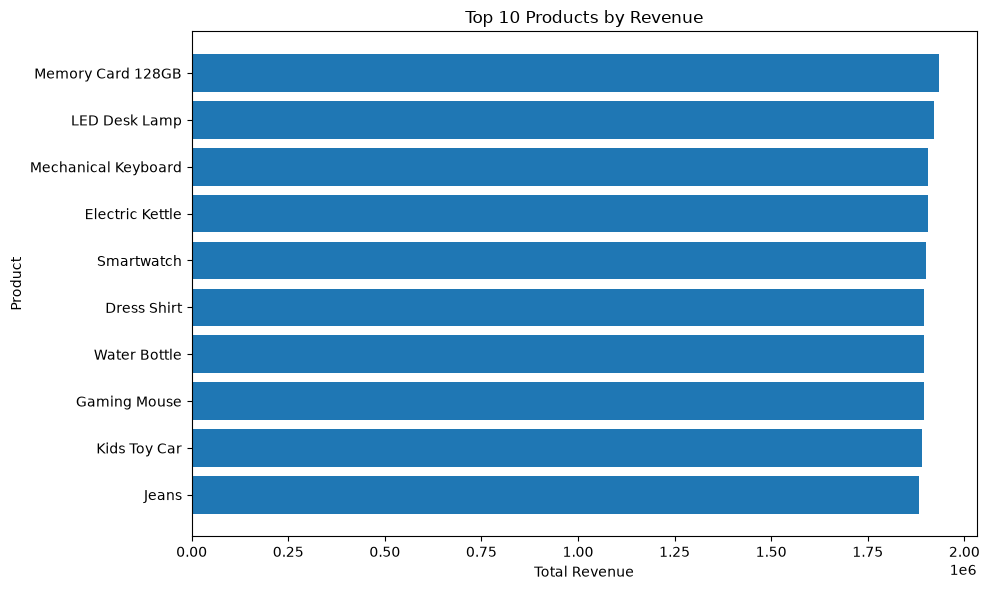

In [48]:
top_products = (
    df.groupby("ProductName")
    .agg(
        TotalRevenue=("TotalAmount", "sum"),
        TotalOrders=("OrderID", "count"),
        CancelledOrders=("OrderStatus", lambda x: (x == "Cancelled").sum())
    )
)

top_products["CancellationRate"] = (
    top_products["CancelledOrders"] / top_products["TotalOrders"] * 100
)

top_products = top_products.sort_values(
    "TotalRevenue",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_products.index,
    top_products["TotalRevenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

# Top revenue products with cancellation risk

plt.figure(figsize=(10, 6))

plt.scatter(
    top_products["TotalRevenue"],
    top_products["CancellationRate"],
    s=100
)

for product in top_products.index:
    plt.annotate(
        product,
        (
            top_products.loc[product, "TotalRevenue"],
            top_products.loc[product, "CancellationRate"]
        ),
        fontsize=8
    )

plt.title("Revenue vs Cancellation Risk – Top Products")
plt.xlabel("Total Revenue")
plt.ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.show()

# Amazon E-Commerce Sales Analysis

## Project Overview
This project analyzes Amazon e-commerce sales data to identify revenue trends, customer behavior, product performance, and order cancellation patterns.

## Key Business Insights

- Electronics generated the highest category revenue at approximately $15.58M.
- Revenue showed fluctuations across the 2020–2024 period, with negative YoY growth in 2021 and 2024.
- Repeat customers contributed approximately 86.43% of total revenue.
- Memory Card 128GB generated the highest revenue among the analyzed products at approximately $1.94M.
- Gaming Mouse had the highest cancellation rate among the top-revenue products at approximately 3.78%.
- Cancellation rates varied across State × Category combinations, with some combinations exceeding 4%.

## Business Recommendations

- Monitor high-revenue products with relatively high cancellation rates.
- Investigate state-category combinations with elevated cancellation rates.
- Focus on retaining repeat customers while improving conversion of one-time customers.
- Analyze cancellation reasons to identify operational or payment-related issues.

## Tools & Technologies
Python | Pandas | Matplotlib | Data Analysis | Data Visualization

## Conclusion
The analysis provides insights into revenue performance, customer retention, product-level performance, and cancellation risk that can support data-driven business decisions.